# Flight price prediction: Random Forest + Extra Trees
Simplified version of `flight_dt.ipynb`. Run from top to bottom in the project folder using `amazon_ml`.

The final model is preserved: 32 features, a log-price target, five folds, 180 trees per forest, and a 50/50 prediction blend in log space. The separate preliminary preprocessing/export cell is omitted because the original training cell reloads raw data and uses a different, richer feature set.

All outputs start empty. Running this notebook trains the models and creates a new submission filename.

## 1. Load data and libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import TargetEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
DATA_DIR = Path('data')

def score(y, prediction):
    return {
        'RMSE': np.sqrt(mean_squared_error(y, prediction)),
        'MAE': mean_absolute_error(y, prediction),
        'R2': r2_score(y, prediction),
    }

def write_submission(test, prediction, filename):
    prediction = np.asarray(prediction)
    assert prediction.shape == (len(test),)
    assert np.isfinite(prediction).all() and (prediction > 0).all()
    result = pd.DataFrame({'id': test['id'].to_numpy(), 'price': prediction})
    assert result['id'].is_unique
    result.to_csv(DATA_DIR / filename, index=False)
    print('Saved:', DATA_DIR / filename)
    return result

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
print('Train:', train.shape, '| Test:', test.shape)
display(pd.DataFrame({'train_missing': train.isna().sum(), 'test_missing': test.isna().sum()}))

Train: (15589, 12) | Test: (3898, 11)


,train_missing,test_missing
airline,3089,799.0
arrival_time,0,0.0
days_left,0,0.0
departure_time,0,0.0
destination_city,0,0.0
duration,3095,776.0
flight,0,0.0
flight_class,0,0.0
id,0,0.0
price,0,NaN


## 2. Quick exploratory analysis

Unique categorical values:


airline               18
flight              1070
source_city            6
departure_time         6
stops                  3
arrival_time           6
destination_city       6
flight_class           2
dtype: int64

,train_min,train_max,test_min,test_max
duration,0.92,38.08,0.92,29.08
days_left,1.00,57.00,1.00,57.00


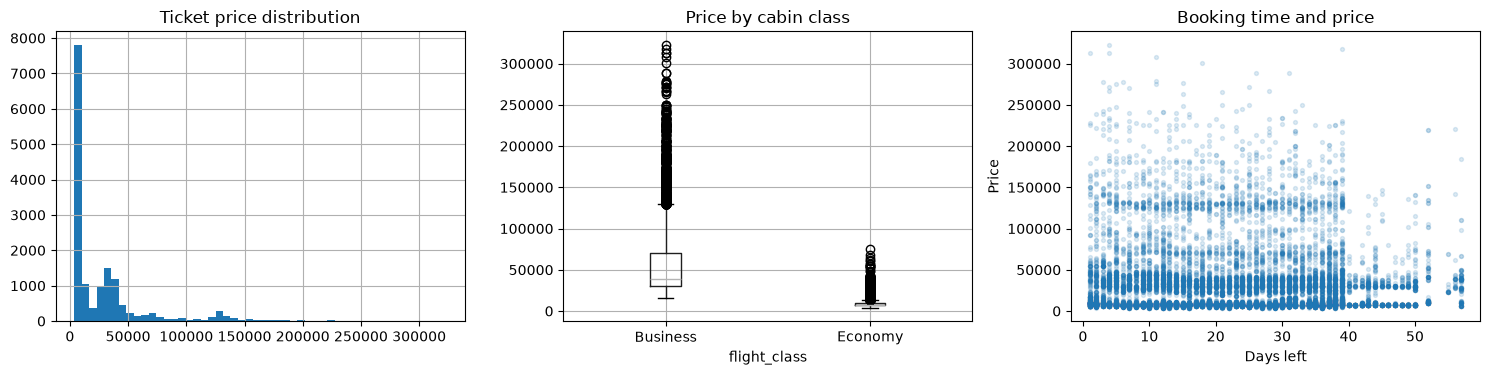

In [3]:
print('Unique categorical values:')
display(train.select_dtypes(include=['object', 'string']).nunique())
display(pd.DataFrame({
    'train_min': train[['duration', 'days_left']].min(),
    'train_max': train[['duration', 'days_left']].max(),
    'test_min': test[['duration', 'days_left']].min(),
    'test_max': test[['duration', 'days_left']].max(),
}))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train['price'].hist(bins=50, ax=axes[0])
axes[0].set_title('Ticket price distribution')
train.boxplot(column='price', by='flight_class', ax=axes[1])
axes[1].set_title('Price by cabin class')
axes[2].scatter(train['days_left'], train['price'], alpha=0.15, s=8)
axes[2].set(xlabel='Days left', ylabel='Price', title='Booking time and price')
fig.suptitle('')
plt.tight_layout()
plt.show()

## 3. Prepare the 32 original features
Recover airline from flight prefixes and fill duration using flight/route, flight, route/stops, then a global median. Add route interactions, booking-time indicators, duration proxies, and frequency counts.

Target encoding is fitted within each training fold. As in the original, feature-only duration lookups use training and application rows together; frequency counts use all training rows. Thus preprocessing is not fully isolated by outer fold. Flight identity helps build features but is not directly target-encoded as a predictor. No scaling is needed for trees.

In [4]:
def original_features(train, test):
    a = train.copy()
    b = test.copy()
    reference = pd.concat([a, b], ignore_index=True)

    reference["flight_prefix"] = (
        reference["flight"].str.split().str[0]
    )

    prefix_map = (
        reference.dropna(subset=["airline"])
        .drop_duplicates("flight_prefix")
        .set_index("flight_prefix")["airline"].to_dict()
    )

    for df in [a, b]:
        df["flight_prefix"] = df["flight"].str.split().str[0]
        df["airline"] = df["airline"].fillna(
            df["flight_prefix"].map(prefix_map)
        )
        df["route"] = (
            df["source_city"] + "_" + df["destination_city"]
        )
        df["airline_class"] = (
            df["airline"] + "_" + df["flight_class"]
        )
        df["route_class"] = (
            df["route"] + "_" + df["flight_class"]
        )
        df["airline_route"] = (
            df["airline"] + "_" + df["route"]
        )
        df["route_stops"] = (
            df["route"] + "_" + df["stops"]
        )

    flight_route_duration = reference.groupby(
        ["flight", "source_city", "destination_city"]
    )["duration"].median().to_dict()

    flight_duration = (
        reference.groupby("flight")["duration"].median().to_dict()
    )
    route_stops_duration = a.groupby(
        ["route", "stops"]
    )["duration"].median().to_dict()

    global_duration = a["duration"].median()

    def recover_duration(row):
        if pd.notna(row["duration"]):
            return row["duration"]

        value = flight_route_duration.get((
            row["flight"], row["source_city"], row["destination_city"]
        ))
        if pd.notna(value):
            return value

        value = flight_duration.get(row["flight"])
        if pd.notna(value):
            return value

        return route_stops_duration.get(
            (row["route"], row["stops"]), global_duration
        )

    for df in [a, b]:
        df["duration"] = df.apply(recover_duration, axis=1)

    minimum_duration = a.groupby("route")["duration"].min().to_dict()

    time_map = {
        "Early_Morning": 0, "Morning": 1, "Afternoon": 2,
        "Evening": 3, "Night": 4, "Late_Night": 5,
    }

    for df in [a, b]:
        df["min_route_dur"] = (
            df["route"].map(minimum_duration).fillna(1.5)
        )
        df["layover_est"] = (
            df["duration"] - df["min_route_dur"]
        ).clip(lower=0)

        df["flight_class_num"] = df["flight_class"].map({
            "Economy": 0, "Business": 1
        })
        df["stops_num"] = df["stops"].map({
            "zero": 0, "one": 1, "two_or_more": 2
        })
        df["dep_time_num"] = (
            df["departure_time"].map(time_map).fillna(-1)
        )
        df["arr_time_num"] = (
            df["arrival_time"].map(time_map).fillna(-1)
        )

        df["is_direct"] = (df["stops_num"] == 0).astype(int)
        df["is_last_minute"] = (df["days_left"] <= 2).astype(int)
        df["is_urgent"] = (df["days_left"] <= 5).astype(int)
        df["is_early_bird"] = (df["days_left"] >= 25).astype(int)
        df["days_left_inv"] = 1 / (df["days_left"] + 1)
        df["days_left_log"] = np.log1p(df["days_left"])
        df["duration_log"] = np.log1p(df["duration"])
        df["duration_per_stop"] = (
            df["duration"] / (df["stops_num"] + 1)
        )
        df["speed_proxy"] = (
            df["min_route_dur"] / (df["duration"] + 0.1)
        )

    for column in ["flight", "airline", "route", "airline_route"]:
        counts = a[column].value_counts().to_dict()
        for df in [a, b]:
            df[f"{column}_freq"] = (
                df[column].map(counts).fillna(0)
            )

    categorical = [
        "flight_prefix", "airline", "source_city", "destination_city",
        "route", "airline_class", "route_class", "airline_route",
        "route_stops", "departure_time", "arrival_time",
    ]

    numerical = [
        "flight_class_num", "stops_num", "dep_time_num", "arr_time_num",
        "duration", "days_left", "min_route_dur", "layover_est",
        "is_direct", "is_last_minute", "is_urgent", "is_early_bird",
        "days_left_inv", "days_left_log", "duration_log",
        "duration_per_stop", "speed_proxy",
        "flight_freq", "airline_freq", "route_freq", "airline_route_freq",
    ]

    return a, b, categorical, numerical

## 4. Train and evaluate
Out-of-fold predictions are evaluated in rupees. RF uses bootstrap samples; Extra Trees uses randomized split thresholds.

In [5]:
def train_forests(training, application, feature_function=original_features):
    # This retains the original feature-only preprocessing protocol.
    A, B, categories, numbers = feature_function(training, application)
    y = training['price'].to_numpy()
    y_log = np.log1p(y)
    oof_rf = np.zeros(len(training))
    oof_et = np.zeros(len(training))
    oof_blend = np.zeros(len(training))
    application_prediction = np.zeros(len(application))
    folds = KFold(5, shuffle=True, random_state=SEED)

    for fold, (fit_index, valid_index) in enumerate(folds.split(A)):
        encoder = TargetEncoder(target_type='continuous', cv=5,
                                smooth='auto', random_state=SEED)
        X_fit = np.column_stack([
            encoder.fit_transform(A.iloc[fit_index][categories], y_log[fit_index]),
            A.iloc[fit_index][numbers].to_numpy(),
        ])
        X_valid = np.column_stack([
            encoder.transform(A.iloc[valid_index][categories]),
            A.iloc[valid_index][numbers].to_numpy(),
        ])
        X_apply = np.column_stack([
            encoder.transform(B[categories]), B[numbers].to_numpy(),
        ])
        assert all(np.isfinite(X).all() for X in [X_fit, X_valid, X_apply])
        settings = dict(n_estimators=180, max_depth=25, min_samples_split=6,
                        min_samples_leaf=2, max_features=0.75,
                        random_state=SEED + fold, n_jobs=-1)
        rf = RandomForestRegressor(**settings)
        et = ExtraTreesRegressor(**settings)
        rf.fit(X_fit, y_log[fit_index])
        et.fit(X_fit, y_log[fit_index])
        rf_log = rf.predict(X_valid)
        et_log = et.predict(X_valid)
        oof_rf[valid_index] = np.expm1(rf_log)
        oof_et[valid_index] = np.expm1(et_log)
        oof_blend[valid_index] = np.expm1((rf_log + et_log) / 2)
        application_prediction += np.expm1(
            (rf.predict(X_apply) + et.predict(X_apply)) / 2
        ) / 5
        rmse = score(y[valid_index], oof_blend[valid_index])['RMSE']
        print(f'Fold {fold + 1}: RMSE={rmse:,.2f}')

    predictions = {'RF': oof_rf, 'ET': oof_et, 'RF + ET': oof_blend}
    results = pd.DataFrame([
        {'model': name, **score(y, prediction)}
        for name, prediction in predictions.items()
    ])
    application_prediction = np.clip(application_prediction, y.min(), y.max())
    return results, oof_blend, application_prediction

In [6]:
results, oof_predictions, test_predictions = train_forests(train, test)
display(results.round(4))

c:\Users\shubh\.conda\envs\idk_ml\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Fold 1: RMSE=9,389.72


c:\Users\shubh\.conda\envs\idk_ml\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Fold 2: RMSE=10,229.41


c:\Users\shubh\.conda\envs\idk_ml\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


...

c:\Users\shubh\.conda\envs\idk_ml\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Fold 4: RMSE=10,914.06


c:\Users\shubh\.conda\envs\idk_ml\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Fold 5: RMSE=9,847.51


,model,RMSE,MAE,R2
0,RF,10425.3633,3207.6640,0.9290
1,ET,10329.7524,3141.5442,0.9303
2,RF + ET,10312.5195,3154.7929,0.9305


## 5. Save predictions

In [7]:
submission = write_submission(test, test_predictions, 'submission_dt_simple.csv')
display(submission.head())

Saved: data\submission_dt_simple.csv


,id,price
0,1,8409.720041
1,2,7249.622078
2,3,29650.816604
3,4,32284.551727
4,5,4428.441007
